Unsupervised Learning Challenge (Customer Segmentation)


Project Overview

In supervised learning, we rely on predefined labels to train our models. However, real-world business data is often unlabeled. In this assignment, you will take on the role of a Data Scientist at a retail corporation.
The marketing team wants to launch targeted campaigns but doesn't know how to categorize their customer base. Your goal is to apply an unsupervised learning algorithm of your choice to discover natural groupings within the customer data.

1. Problem Statement

Given an unlabeled dataset containing customer demographics and purchasing behavior metrics, you must develop an unsupervised clustering model to segment customers into distinct, actionable cohorts. The final model should help the business identify who their high-value, budget-conscious, or impulsive shoppers are without using any prior manual classification.

2. Dataset Instructions

You will use the classic Mall Customers Dataset.
• How to get the data: You can download the dataset directly from Kaggle (Search for: Mall Customers Dataset) or use the direct CSV link provided by your instructor.
• Dataset Features:
	• CustomerID: Unique ID assigned to the customer (Note: This is an identifier, not a pattern feature).
	• Gender: Categorical gender of the customer.
	• Age: Age of the customer in years.
	• Annual Income (k$): Annual income of the customer in thousands of dollars.
	• Spending Score (1-100): A score assigned by the store based on customer behavior and purchase history.

3. Required Tasks (Student Checklist)

Your submission must document the following five implementation steps:
• Exploratory Data Analysis (EDA): Handle missing values (if any), check data types, and generate visual distributions (histograms/scatter plots) of the features.
• Data Preprocessing: Drop irrelevant identifier columns. Scale the numeric features properly using standardization or normalization so no single feature dominates the distance metrics.
• Finding Optimal Clusters (K): Implement a method to determine the best number of clusters. You must explicitly show either the Elbow Method (WCSS plot) or a Silhouette Analysis plot to justify your choice of K.
• Model Implementation: Select and apply an unsupervised clustering algorithm (such as K-Means, Agglomerative Hierarchical Clustering, or DBSCAN) using your chosen optimal number of clusters.
• Business Insights: Visualize the final clusters (e.g., a 2D scatter plot of Annual Income vs. Spending Score colored by cluster). Write a brief interpretation naming each customer segment (e.g., "Sensible Spenders", "High-Income/High-Spend Targets").

4. Submission Deliverables

Students must submit a single compressed folder (.zip) named FirstName_LastName_Assignment.zip containing:
1. Jupyter Notebook (.ipynb): Clean, well-commented, and fully executed Python code showing all graphs and outputs.
2. Project Report (.pdf or included as Markdown in the notebook): A concise summary explaining your preprocessing choices, your justification for the selected number of clusters, and the final business descriptions of your segments.


In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import warnings 
warnings.filterwarnings("ignore")

In [52]:
df=pd.read_csv("Mall_Customers.csv")
print(df.head())

print(df.dtypes)

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [53]:
print(df.isna().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [74]:
print(df.shape)

(200, 5)


In [54]:
print(df.describe(include="all").T)

                        count unique     top freq   mean        std   min  \
CustomerID              200.0    NaN     NaN  NaN  100.5  57.879185   1.0   
Gender                    200      2  Female  112    NaN        NaN   NaN   
Age                     200.0    NaN     NaN  NaN  38.85  13.969007  18.0   
Annual Income (k$)      200.0    NaN     NaN  NaN  60.56  26.264721  15.0   
Spending Score (1-100)  200.0    NaN     NaN  NaN   50.2  25.823522   1.0   

                          25%    50%     75%    max  
CustomerID              50.75  100.5  150.25  200.0  
Gender                    NaN    NaN     NaN    NaN  
Age                     28.75   36.0    49.0   70.0  
Annual Income (k$)       41.5   61.5    78.0  137.0  
Spending Score (1-100)  34.75   50.0    73.0   99.0  


In [55]:
print(df["Gender"].value_counts(dropna=False))

Gender
Female    112
Male       88
Name: count, dtype: int64


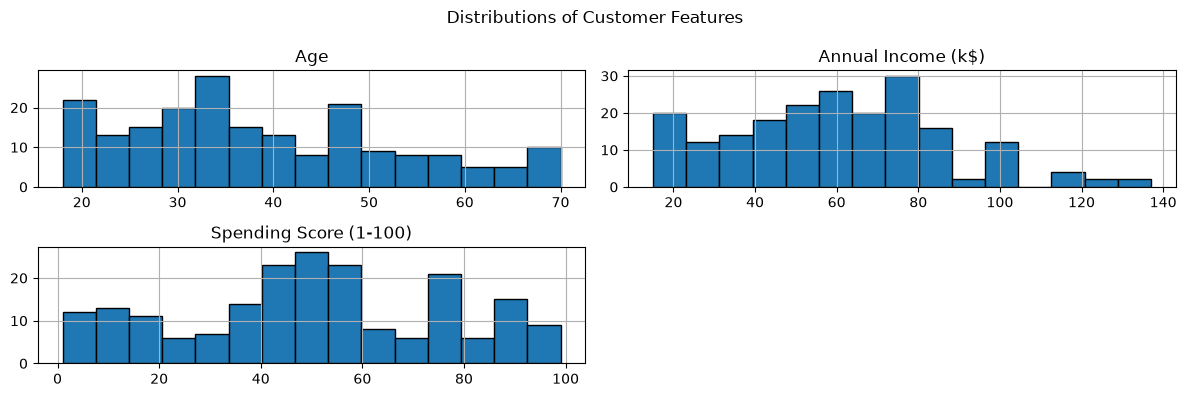

In [56]:
number_for_eda = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
df[number_for_eda].hist(figsize=(12, 4), bins=15, edgecolor="black")
plt.suptitle("Distributions of Customer Features")
plt.tight_layout()
plt.show()

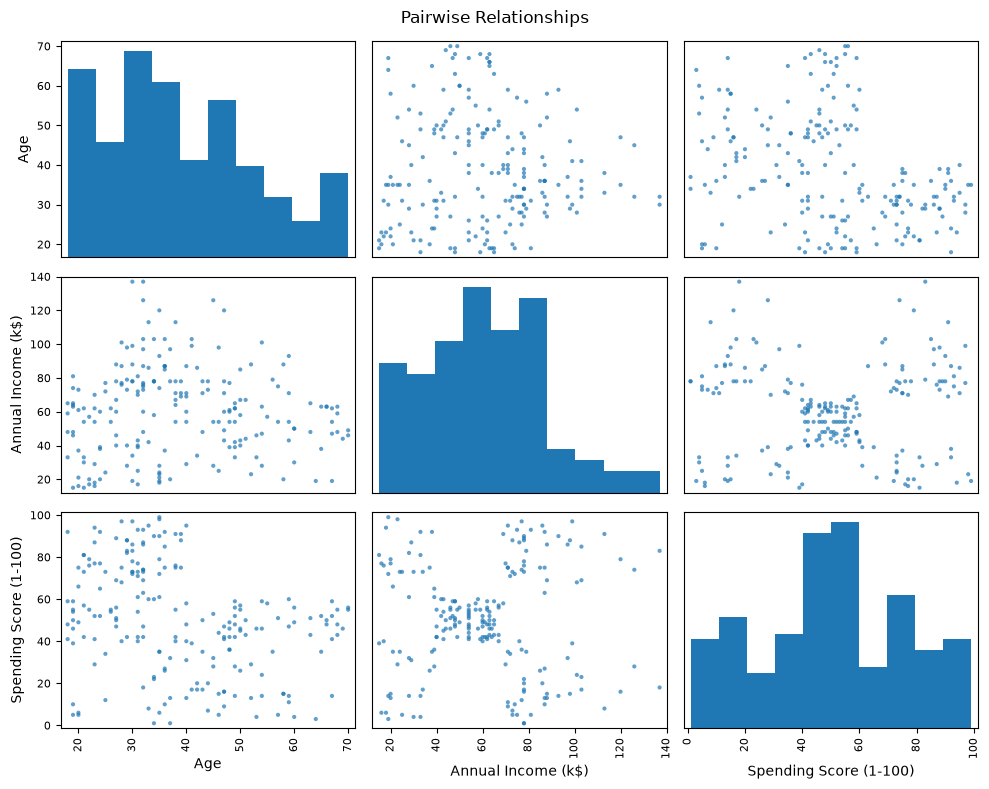

In [57]:
from pandas.plotting import scatter_matrix
scatter_matrix(df[number_for_eda], figsize=(10, 8), diagonal="hist", alpha=0.7)
plt.suptitle("Pairwise Relationships")
plt.tight_layout()
plt.show()

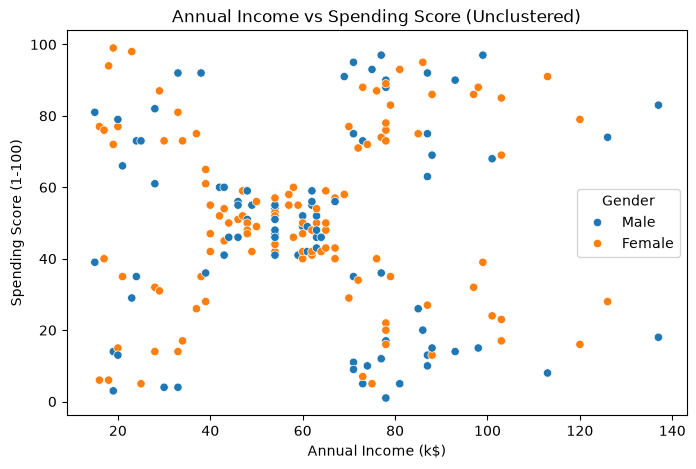

In [58]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Gender")
plt.title("Annual Income vs Spending Score (Unclustered)")
plt.show()

In [59]:
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

In [60]:
model_data = df[features].copy()
if model_data.isna().sum().sum() > 0:
    model_data = model_data.fillna(model_data.median())

In [61]:
finite_mask = np.isfinite(model_data).all(axis=1)
if not finite_mask.all():
    print("Removing non-finite rows:", int((~finite_mask).sum()))
    model_data = model_data.loc[finite_mask].copy()
    df_model = df.loc[finite_mask].copy()
else:
    df_model = df.copy()

In [62]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(model_data)
print("Features used:", features)
print("Scaled matrix shape:", X_scaled.shape)
print("Scaled feature means (approximately zero):", X_scaled.mean(axis=0).round(3))
print("Scaled feature standard deviations (approximately one):", X_scaled.std(axis=0).round(3))

Features used: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Scaled matrix shape: (200, 3)
Scaled feature means (approximately zero): [-0. -0. -0.]
Scaled feature standard deviations (approximately one): [1. 1. 1.]


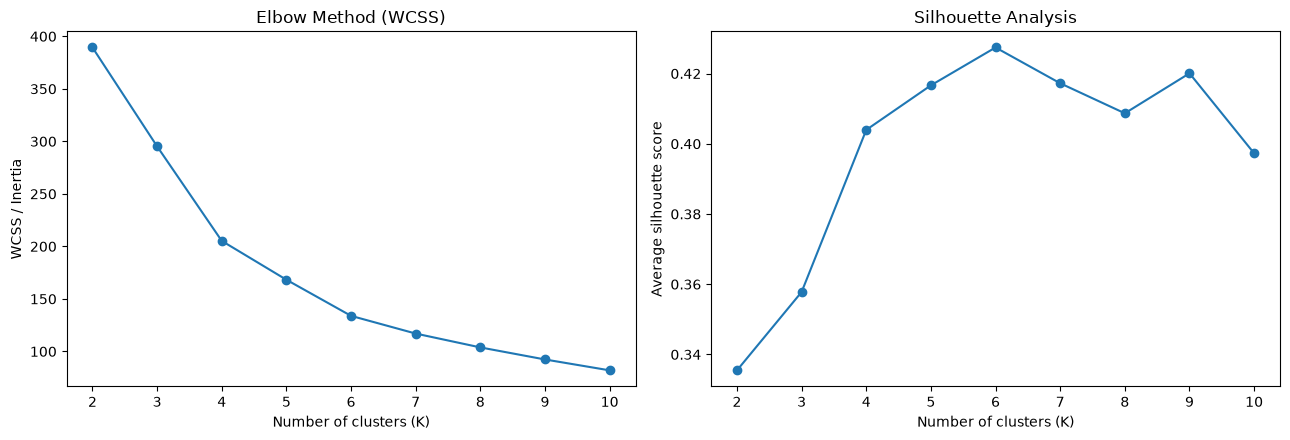

,K,WCSS,Silhouette Score
0,2,389.3862,0.3355
1,3,295.2122,0.3578
2,4,205.2251,0.4040
3,5,168.2476,0.4166
4,6,133.8683,0.4274
5,7,117.0116,0.4172
6,8,103.8286,0.4087
7,9,92.3495,0.4201
8,10,81.9871,0.3973


In [63]:
k_values = range(2, 11)
wcss = []
silhouette_scores = []
for k in k_values:
    candidate = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = candidate.fit_predict(X_scaled)
    wcss.append(candidate.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_values), wcss, marker="o")
axes[0].set_title("Elbow Method (WCSS)")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("WCSS / Inertia")
axes[0].set_xticks(list(k_values))
axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Average silhouette score")
axes[1].set_xticks(list(k_values))
plt.tight_layout()
plt.show()
selection_results = pd.DataFrame({
    "K": list(k_values),
    "WCSS": wcss,
    "Silhouette Score": silhouette_scores
})
display(selection_results.round(4))

In [64]:
best_k = int(selection_results.loc[selection_results["Silhouette Score"].idxmax(), "K"])
print("K with highest silhouette score:", best_k)

K with highest silhouette score: 6


In [65]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(X_scaled)

In [66]:
segmented = df_model.copy()
segmented["Cluster"] = cluster_labels
print("Cluster sizes:")
display(segmented["Cluster"].value_counts().sort_index().rename("Customers").to_frame())

Cluster sizes:


,Customers
Cluster,
0,33
1,45
2,24
3,39
4,38
5,21


In [67]:
cluster_profile = segmented.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(1)
cluster_profile["Customer_Percentage"] = (
    100 * cluster_profile["Customer_Count"] / len(segmented)
).round(1)
print("Cluster profiles:")
display(cluster_profile)

Cluster profiles:


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score,Customer_Percentage
Cluster,,,,,
0,33,41.9,88.9,17.0,16.5
1,45,56.3,54.3,49.1,22.5
2,24,25.2,25.8,76.9,12.0
3,39,32.7,86.5,82.1,19.5
4,38,26.7,57.6,47.8,19.0
5,21,45.5,26.3,19.4,10.5


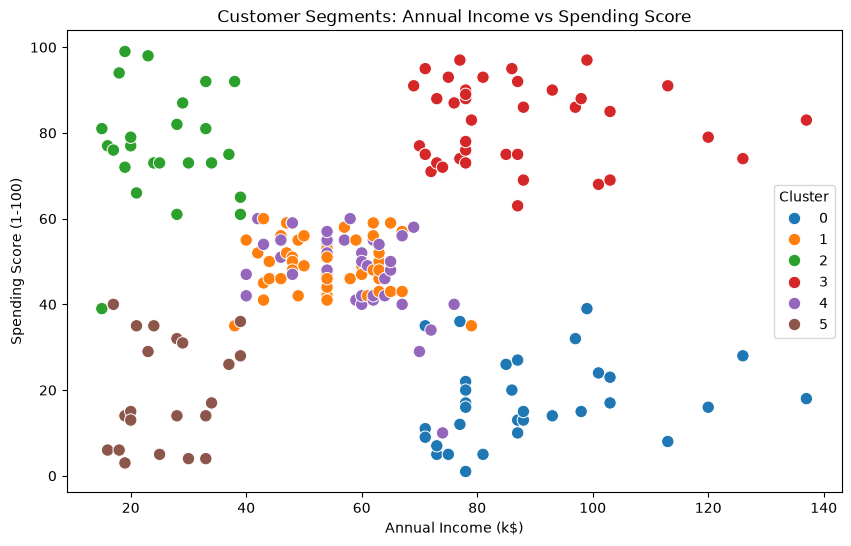

In [68]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=segmented,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=80)
plt.title("Customer Segments: Annual Income vs Spending Score")
plt.legend(title="Cluster")
plt.show()

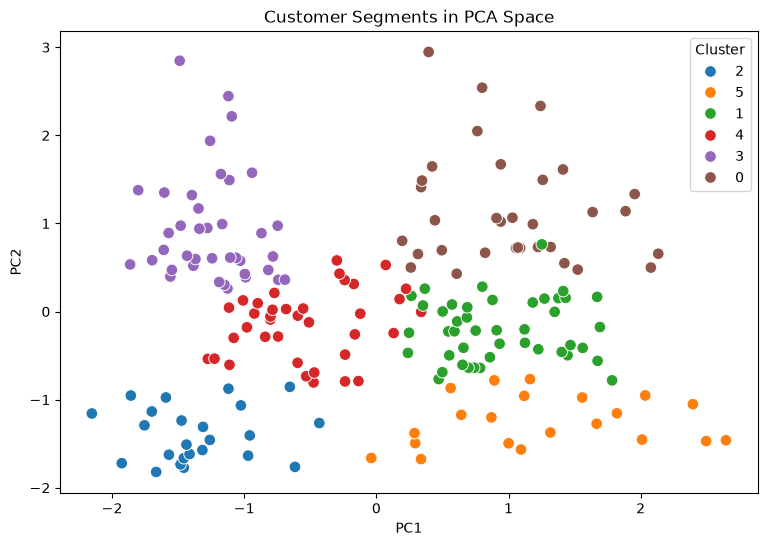

PCA explained variance ratio: [0.443 0.333]
Total variance represented by 2 components: 0.776


In [69]:
pca = PCA(n_components=2, random_state=42)
pca_points = pca.fit_transform(X_scaled)
pca_plot = pd.DataFrame({
    "PC1": pca_points[:, 0],
    "PC2": pca_points[:, 1],
    "Cluster": cluster_labels.astype(str)
})
plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=70)
plt.title("Customer Segments in PCA Space")
plt.show()
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total variance represented by 2 components:",
round(pca.explained_variance_ratio_.sum(), 3))

Predicted clusters for unseen customers:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Predicted_Cluster
0,U1,23,25,78,2
1,U2,44,90,18,0
2,U3,32,88,85,3
3,U4,57,52,48,1
4,U5,27,58,50,4
5,U6,46,24,20,5


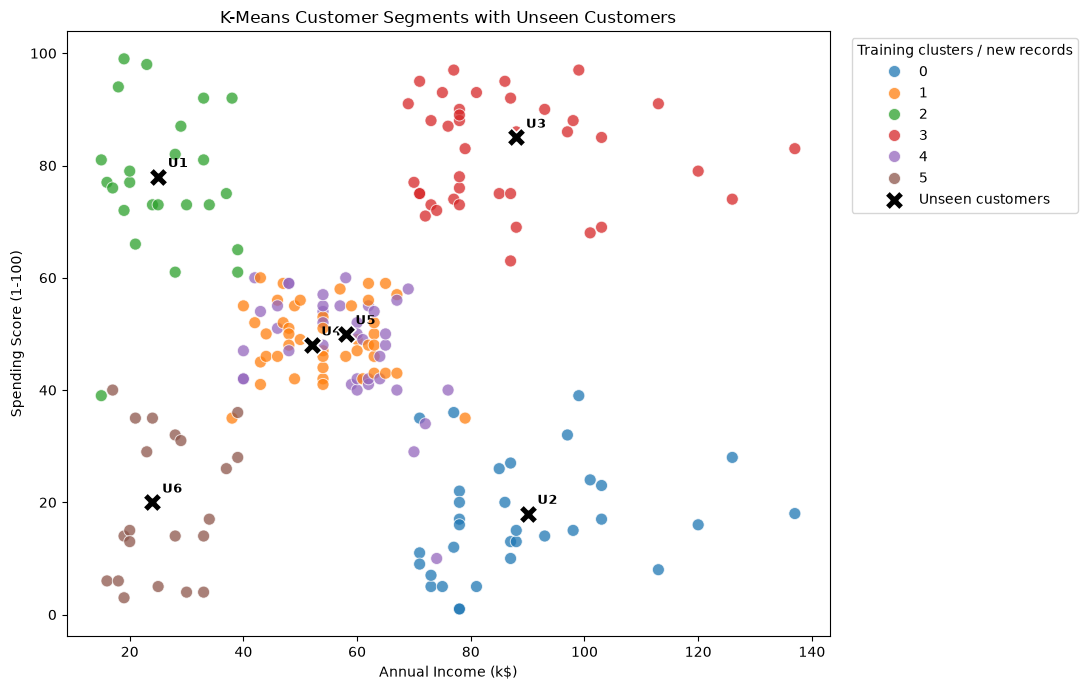

Unseen records tested: 6
Predictions saved to Unseen_Customer_Predictions.csv


In [80]:
unseen_customers = pd.read_csv("Unseen_Customers_Test.csv")
unseen_features = unseen_customers[features].copy()
unseen_scaled = scaler.transform(unseen_features)
uns_prediction = kmeans.predict(unseen_scaled)
unseen_results = unseen_customers.copy()
unseen_results["Predicted_Cluster"] = uns_prediction
print("Predicted clusters for unseen customers:")
display(unseen_results)
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=segmented,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=75,
    alpha=0.75
)
plt.scatter(
    unseen_results["Annual Income (k$)"],
    unseen_results["Spending Score (1-100)"],
    color="black",
    marker="X",
    s=190,
    edgecolors="white",
    linewidths=1.2,
    label="Unseen customers",
    zorder=5
)
for _, row in unseen_results.iterrows():
    plt.annotate(
        row["CustomerID"],
        (row["Annual Income (k$)"], row["Spending Score (1-100)"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

plt.title("K-Means Customer Segments with Unseen Customers")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Training clusters / new records", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
unseen_results.to_csv("Unseen_Customer_Predictions.csv", index=False)
print("Unseen records tested:", len(unseen_results))
print("Predictions saved to Unseen_Customer_Predictions.csv")


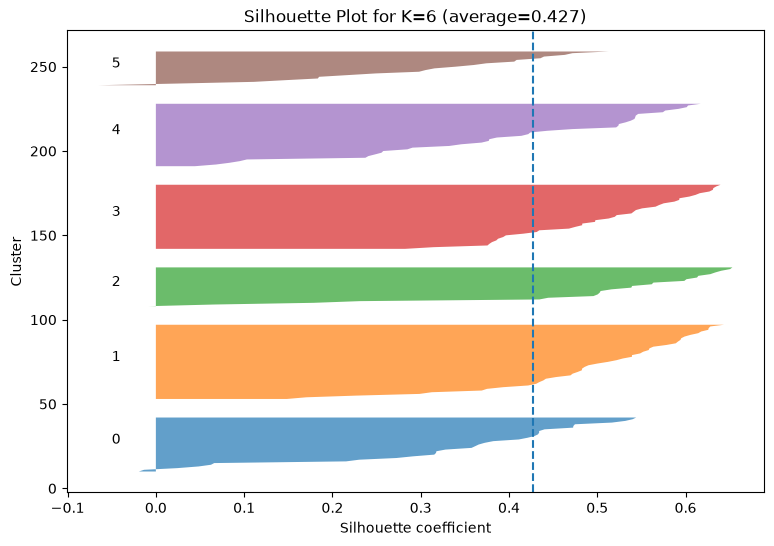

In [81]:
sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)
y_lower = 10
plt.figure(figsize=(9, 6))
for cluster_id in range(best_k):
    cluster_values = sample_silhouette_values[cluster_labels == cluster_id]
    cluster_values.sort()
    size = cluster_values.shape[0]
    y_upper = y_lower + size
    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_values,
        alpha=0.7
    )
    plt.text(-0.05, y_lower + 0.5 * size, str(cluster_id))
    y_lower = y_upper + 10
average_score = silhouette_score(X_scaled, cluster_labels)
plt.axvline(average_score, linestyle="--")
plt.title(f"Silhouette Plot for K={best_k} (average={average_score:.3f})")
plt.xlabel("Silhouette coefficient")
plt.ylabel("Cluster")
plt.show()


In [82]:
income_median = segmented["Annual Income (k$)"].median()
spending_median = segmented["Spending Score (1-100)"].median()
def describe_segment(row):
    high_income = row["Average_Annual_Income"] >= income_median
    high_spend = row["Average_Spending_Score"] >= spending_median
    if high_income and high_spend:
        return "High-Income / High-Spend Targets"
    if high_income and not high_spend:
        return "Affluent, Low-Spend Customers"
    if not high_income and high_spend:
        return "Budget-Conscious / Enthusiastic Shoppers"
    return "Low-Income / Low-Spend Customers"
business_profile = cluster_profile.copy()
business_profile["Suggested_Segment_Name"] = business_profile.apply(describe_segment, axis=1)
recommendations = {
    "High-Income / High-Spend Targets":
        "Prioritize loyalty rewards, premium launches, VIP experiences and personalized offers.",
    "Affluent, Low-Spend Customers":
        "Test personalized recommendations, product education and carefully targeted incentives.",
    "Budget-Conscious / Enthusiastic Shoppers":
        "Promote value bundles, seasonal discounts and affordable loyalty rewards.",
    "Low-Income / Low-Spend Customers":
        "Use low-cost promotions and practical essentials; avoid expensive acquisition campaigns."
}
business_profile["Marketing_Recommendation"] = business_profile["Suggested_Segment_Name"].map(recommendations)
display(business_profile)
print("Overall silhouette score:", round(average_score, 4))
print("Chosen K:", best_k)
print("Note: These are descriptive cohort labels based on median income/spending.")
print("Validate campaign performance with future experiments before deployment.")


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score,Customer_Percentage,Suggested_Segment_Name,Marketing_Recommendation
Cluster,,,,,,,
0,33,41.9,88.9,17.0,16.5,"Affluent, Low-Spend Customers","Test personalized recommendations, product edu..."
1,45,56.3,54.3,49.1,22.5,Low-Income / Low-Spend Customers,Use low-cost promotions and practical essentia...
2,24,25.2,25.8,76.9,12.0,Budget-Conscious / Enthusiastic Shoppers,"Promote value bundles, seasonal discounts and ..."
3,39,32.7,86.5,82.1,19.5,High-Income / High-Spend Targets,"Prioritize loyalty rewards, premium launches, ..."
4,38,26.7,57.6,47.8,19.0,Low-Income / Low-Spend Customers,Use low-cost promotions and practical essentia...
5,21,45.5,26.3,19.4,10.5,Low-Income / Low-Spend Customers,Use low-cost promotions and practical essentia...


Overall silhouette score: 0.4274
Chosen K: 6
Note: These are descriptive cohort labels based on median income/spending.
Validate campaign performance with future experiments before deployment.


In [83]:
segmented.to_csv("customer_segments.csv", index=False)
business_profile.to_csv("business_segment_profile.csv")
print("Saved: customer_segments.csv and business_segment_profile.csv")

Saved: customer_segments.csv and business_segment_profile.csv


# Justification

K-Means groups customers by similarity across age, annual income and spending score. The Elbow and Silhouette plots provide evidence for selecting K=6 as clusters and Silhouette score is 0.427. The profile table translates numerical clusters into marketing cohorts.